# Student Placement Prediction
An end-to-end Machine Learning pipeline predicting campus placement outcomes based on student academic performance (CGPA) and cognitive ability (IQ).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from mlxtend.plotting import plot_decision_regions
import pickle


## 1. Load Dataset & Exploratory Data Analysis


In [2]:
df = pd.read_csv("placement.csv")
df.head()


,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [4]:
df.describe()


,Unnamed: 0,cgpa,iq,placement
count,100.000000,100.000000,100.000000,100.000000
mean,49.500000,5.991000,123.580000,0.500000
std,29.011492,1.143634,39.944198,0.502519
min,0.000000,3.300000,37.000000,0.000000
25%,24.750000,5.075000,101.500000,0.000000
50%,49.500000,6.000000,127.500000,0.500000
75%,74.250000,6.900000,149.000000,1.000000
max,99.000000,8.500000,233.000000,1.000000


### Drop Unnamed Index Column


In [5]:
df = df.iloc[:, 1:]
df.head()


,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


### Visualize Feature Distribution


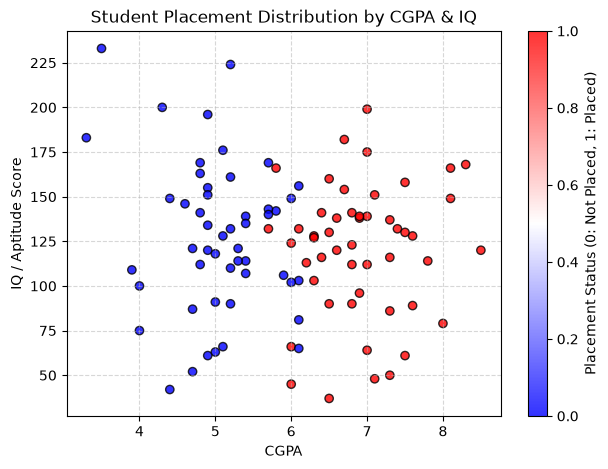

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(df['cgpa'], df['iq'], c=df['placement'], cmap='bwr', alpha=0.8, edgecolors='k')
plt.xlabel("CGPA")
plt.ylabel("IQ / Aptitude Score")
plt.title("Student Placement Distribution by CGPA & IQ")
plt.colorbar(label="Placement Status (0: Not Placed, 1: Placed)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


## 2. Feature Selection & Train-Test Split
Using `test_size=0.2`, `random_state=42`, and `stratify=y` for reproducible, balanced evaluation.


In [7]:
X = df.iloc[:, :2]
y = df.iloc[:, 2]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")


Training samples: 80, Testing samples: 20


## 3. Build & Train Model Pipeline
Encapsulating `StandardScaler` and `LogisticRegression` inside a `Pipeline` to eliminate data leakage and export a single unified model artifact.


In [8]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=42))
])

pipeline.fit(X_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(random_state=42))])

## 4. Model Evaluation
### Cross-Validation


In [9]:
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')
print(f"5-Fold Cross-Validation Scores: {cv_scores.round(4)}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


5-Fold Cross-Validation Scores: [0.9375 0.875  0.9375 0.875  0.9375]
Mean CV Accuracy: 0.9125 (+/- 0.0306)


### Test Set Performance Metrics


In [10]:
y_pred = pipeline.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Test Accuracy  : {acc:.4f}")
print(f"Precision Score: {prec:.4f}")
print(f"Recall Score   : {rec:.4f}")
print(f"F1 Score       : {f1:.4f}\n")
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Not Placed", "Placed"]))


Test Accuracy  : 0.8500
Precision Score: 0.8889
Recall Score   : 0.8000
F1 Score       : 0.8421

Classification Report:

              precision    recall  f1-score   support

  Not Placed       0.82      0.90      0.86        10
      Placed       0.89      0.80      0.84        10

    accuracy                           0.85        20
   macro avg       0.85      0.85      0.85        20
weighted avg       0.85      0.85      0.85        20



### Confusion Matrix


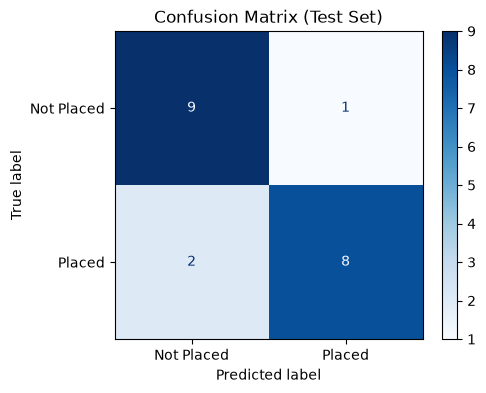

In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Placed", "Placed"])
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Confusion Matrix (Test Set)")
plt.show()


## 5. Decision Boundary Visualization


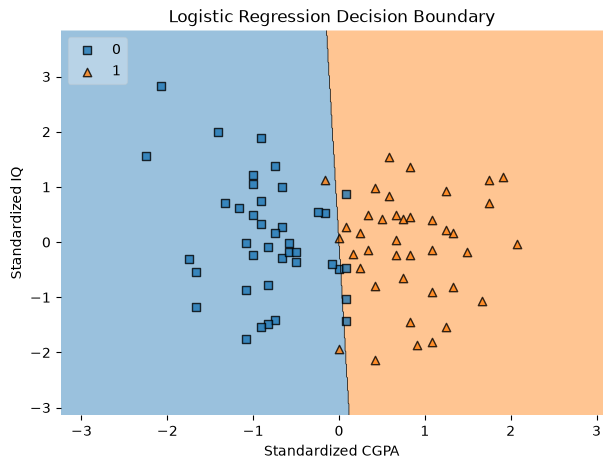

In [12]:
# Extract the fitted scaler and classifier to visualize the decision boundary in scaled feature space
scaled_X_train = pipeline.named_steps['scaler'].transform(X_train.values)
clf = pipeline.named_steps['classifier']

fig, ax = plt.subplots(figsize=(7, 5))
plot_decision_regions(scaled_X_train, y_train.values, clf=clf, legend=2, ax=ax)
plt.xlabel("Standardized CGPA")
plt.ylabel("Standardized IQ")
plt.title("Logistic Regression Decision Boundary")
plt.show()


## 6. Model Serialization
Saving the unified pipeline (`StandardScaler` + `LogisticRegression`) as `model.pkl`.


In [13]:
with open("model.pkl", "wb") as f:
    pickle.dump(pipeline, f)
print("Pipeline successfully saved to model.pkl!")


Pipeline successfully saved to model.pkl!
